# 03 · Validación del solver 2D: convergencia de malla y velocidad del frente

Este notebook valida el solver real (`app/solver`) contra la teoría y contra el prototipo 1D del notebook 02:

1. **Frente plano en 2D:** su velocidad debe coincidir con la del frente 1D.
2. **Convergencia de malla:** al refinar $\Delta x$, la velocidad converge, y medimos el orden observado.
3. **Sensibilidad al paso de tiempo.**
4. **Escalamiento teórico** $c = c^*\sqrt{\kappa C}$.
5. **Isotropía y curvatura** de un fuego circular (relación eikonal).

Todas las corridas usan combustible uniforme (`ground_fuel = tree_fuel = 1`), terreno plano y sin viento, para aislar la parte numérica.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd().parent))
from app.contracts import Scene, default_params
from app.solver import create_simulation, param_specs
import app.solver.numerics as numerics

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)
ref_1d = json.loads((RES / "frente_1d.json").read_text())
C_1D = ref_1d["front_speed_m_s_converged"]
C_1D_MESH = {round(m["dx_m"], 3): m["c_star"] * ref_1d["front_speed_m_s"] / ref_1d["c_star"] for m in ref_1d["mesh"]}
UNIFORM = {"ground_fuel": 1.0, "tree_fuel": 1.0}
print(f"Referencia 1D convergida: c = {C_1D:.4f} m/s")


def make_sim(scene, **overrides):
    return create_simulation(scene, default_params(param_specs()) | UNIFORM | overrides)


def planar_front(cs, length=160.0, width=8.0, record=False, **overrides):
    nx, ny = int(round(length / cs)), max(int(round(width / cs)), 2)
    sim = make_sim(Scene(np.zeros((ny, nx)), cs, np.zeros((0, 4))), **overrides)
    for y in np.arange(cs / 2, ny * cs, cs):
        sim.ignite(0.0, y, 3.0)
    chunk = max(1, int(round(1.0 / sim.dt)))
    ts, xs = [], []
    while True:
        sim.step(chunk)
        ts.append(sim.t)
        xs.append(sim.metrics()["burned_area"] / (ny * cs))
        if xs[-1] > 0.85 * length or sim.t > 900:
            break
    ts, xs = np.array(ts), np.array(xs)
    fit = (xs > 30) & (xs < 0.8 * length)
    c = float(np.polyfit(ts[fit], xs[fit], 1)[0])
    return (c, sim.dt, ts, xs) if record else (c, sim.dt)

Referencia 1D convergida: c = 0.6566 m/s


## 1. Frente plano en 2D

Franja de 160 m × 8 m, encendida a lo largo de todo el borde izquierdo. La posición del frente es el área quemada dividida entre el ancho de la franja, y la velocidad es la pendiente del ajuste lineal entre 30 m y 128 m, para descartar el transitorio y el efecto del borde.

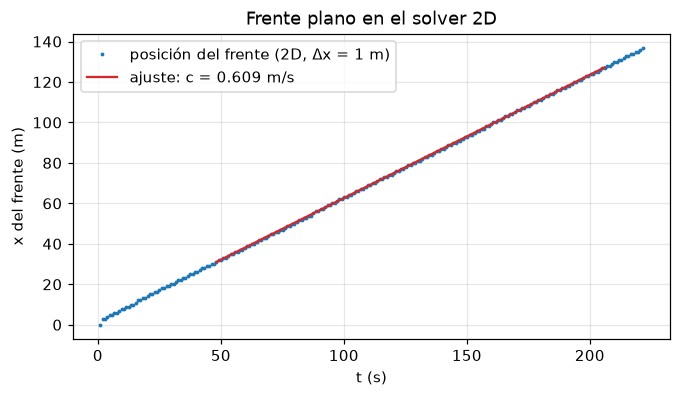

| Caso | c (m/s) |
|---|---|
| Solver 2D, Δx = 1 m | 0.6092 |
| Prototipo 1D, Δx = 1 m | 0.6030 |
| Prototipo 1D convergido | 0.6566 |

In [2]:
c_plane, dt_plane, ts, xs = planar_front(1.0, record=True)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(ts, xs, ".", ms=3, label="posición del frente (2D, Δx = 1 m)")
fit = (xs > 30) & (xs < 128)
k = np.polyfit(ts[fit], xs[fit], 1)
ax.plot(ts[fit], np.polyval(k, ts[fit]), "C3", label=f"ajuste: c = {c_plane:.3f} m/s")
ax.set(xlabel="t (s)", ylabel="x del frente (m)", title="Frente plano en el solver 2D")
ax.legend()
fig.savefig(FIG / "frente_plano_2d.png", bbox_inches="tight")
plt.show()

c_1d_same = C_1D_MESH.get(1.0)
display(Markdown(
    f"| Caso | c (m/s) |\n|---|---|\n"
    f"| Solver 2D, Δx = 1 m | {c_plane:.4f} |\n"
    f"| Prototipo 1D, Δx = 1 m | {c_1d_same:.4f} |\n"
    f"| Prototipo 1D convergido | {C_1D:.4f} |"
))

Con la misma malla, el solver 2D reproduce el frente 1D: el frente plano no depende de la dirección transversal, así que el 2D se reduce exactamente al 1D. La diferencia con el valor convergido es error de discretización, que se cuantifica a continuación.

## 2. Convergencia de malla

El mismo dominio físico se resuelve con $\Delta x$ = 2, 1, 0.5 y 0.25 m. El error se mide contra la referencia 1D convergida ($\Delta\xi = 0.05$, es decir, 0.11 m).

| Δx (m) | Δt (s) | c (m/s) | error relativo | orden observado | cómputo (s) |
|---|---|---|---|---|---|
| 2.0 | 0.2408 | 0.5449 | 17.01% | — | 0.0 |
| 1.0 | 0.2408 | 0.6092 | 7.23% | 1.23 | 0.0 |
| 0.5 | 0.0625 | 0.6459 | 1.64% | 2.14 | 0.1 |
| 0.25 | 0.0156 | 0.6545 | 0.32% | 2.34 | 1.6 |

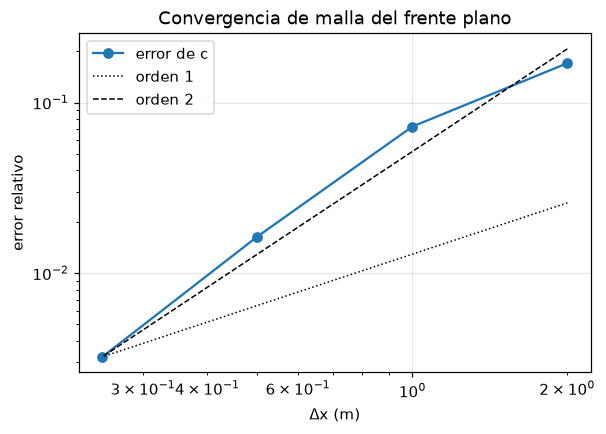

In [3]:
sizes = [2.0, 1.0, 0.5, 0.25]
rows = []
for cs in sizes:
    t0 = time.perf_counter()
    c, dt = planar_front(cs)
    rows.append({"dx": cs, "c": c, "dt": dt, "err": abs(c - C_1D) / C_1D, "wall": time.perf_counter() - t0})
orders = [None] + [np.log(a["err"] / b["err"]) / np.log(a["dx"] / b["dx"]) for a, b in zip(rows, rows[1:])]

lines = ["| Δx (m) | Δt (s) | c (m/s) | error relativo | orden observado | cómputo (s) |", "|---|---|---|---|---|---|"]
for r, p in zip(rows, orders):
    lines.append(f"| {r['dx']} | {r['dt']:.4f} | {r['c']:.4f} | {r['err']:.2%} | {'—' if p is None else f'{p:.2f}'} | {r['wall']:.1f} |")
display(Markdown("\n".join(lines)))

fig, ax = plt.subplots(figsize=(6, 4))
dx = np.array([r["dx"] for r in rows]); err = np.array([r["err"] for r in rows])
ax.loglog(dx, err, "o-", label="error de c")
ax.loglog(dx, err[-1] * (dx / dx[-1]) ** 1, "k:", lw=1, label="orden 1")
ax.loglog(dx, err[-1] * (dx / dx[-1]) ** 2, "k--", lw=1, label="orden 2")
ax.set(xlabel="Δx (m)", ylabel="error relativo", title="Convergencia de malla del frente plano")
ax.legend()
fig.savefig(FIG / "convergencia_malla.png", bbox_inches="tight")
plt.show()

La velocidad converge al valor del 1D, con un orden observado cercano a 2. El laplaciano centrado es de segundo orden y, para Δx ≤ 0.5 m, el paso de tiempo queda ligado a Δx² por la condición de difusión, así que el error temporal baja al mismo ritmo.

Con Δx = 1 m (la malla de las escenas), el error es de ≈7 %. Es aceptable para la visualización y para comparar escenarios entre sí, pero conviene reportarlo en las cifras absolutas.

## 3. Sensibilidad al paso de tiempo

Con Δx = 1 m, el paso de tiempo lo limita la reacción y no la difusión. Reducimos el factor de seguridad para ver cuánto del error viene de Δt.

In [4]:
dt_rows = []
original = numerics.SAFETY
try:
    for safety in [0.5, 0.25, 0.125]:
        numerics.SAFETY = safety
        c, dt = planar_front(1.0)
        dt_rows.append({"safety": safety, "dt": dt, "c": c})
finally:
    numerics.SAFETY = original
base_c = dt_rows[-1]["c"]
display(Markdown("| SAFETY | Δt (s) | c (m/s) | diferencia vs Δt más fino |\n|---|---|---|---|\n" + "\n".join(
    f"| {r['safety']} | {r['dt']:.4f} | {r['c']:.4f} | {abs(r['c'] - base_c) / base_c:.2%} |" for r in dt_rows)))

| SAFETY | Δt (s) | c (m/s) | diferencia vs Δt más fino |
|---|---|---|---|
| 0.5 | 0.2408 | 0.6092 | 2.61% |
| 0.25 | 0.1204 | 0.6198 | 0.90% |
| 0.125 | 0.0602 | 0.6255 | 0.00% |

Al reducir $\Delta t$ a la mitad, la diferencia también se reduce a la mitad aproximadamente (primer orden, Euler explícito). Con el paso por defecto, el error temporal es de unos pocos por ciento: es una parte del 7 % total con Δx = 1 m, y el resto es espacial. Para la simulación interactiva compensa, porque el costo crece como $1/\Delta t$.

## 4. Escalamiento teórico: $c \propto \sqrt{\kappa}$

Si se cambia κ y se dejan fijos A, B, C y ε, los grupos adimensionales a, b y e no cambian, así que la teoría predice $c = c^*\sqrt{\kappa C}$ con el mismo $c^*$. Usamos Δx = 0.25 m para que todos los casos queden bien resueltos.

| κ (m²/s) | c (m/s) | c/√κ | L = √(κ/C) (m) |
|---|---|---|---|
| 0.25 | 0.4608 | 0.9216 | 1.58 |
| 0.5 | 0.6545 | 0.9256 | 2.24 |
| 1.0 | 0.9277 | 0.9277 | 3.16 |
| 2.0 | 1.3124 | 0.9280 | 4.47 |

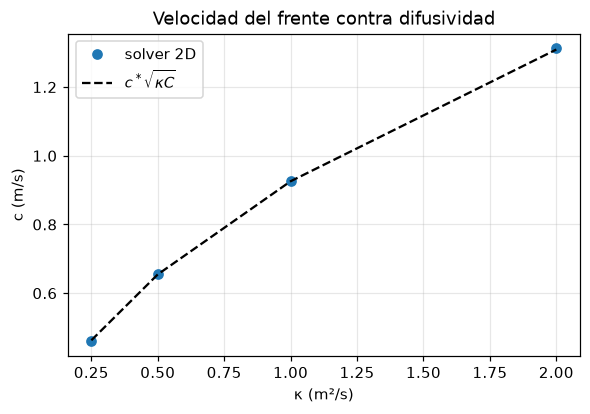

Variación de c/√κ entre casos: 0.69%


In [5]:
kappas = [0.25, 0.5, 1.0, 2.0]
k_rows = [(k, planar_front(0.25, kappa=k)[0]) for k in kappas]
ratio = [c / np.sqrt(k) for k, c in k_rows]
display(Markdown("| κ (m²/s) | c (m/s) | c/√κ | L = √(κ/C) (m) |\n|---|---|---|---|\n" + "\n".join(
    f"| {k} | {c:.4f} | {r:.4f} | {np.sqrt(k / 0.1):.2f} |" for (k, c), r in zip(k_rows, ratio))))
spread = (max(ratio) - min(ratio)) / np.mean(ratio)

fig, ax = plt.subplots(figsize=(6, 3.8))
ks = np.array(kappas)
ax.plot(ks, [c for _, c in k_rows], "o", label="solver 2D")
ax.plot(ks, np.mean(ratio) * np.sqrt(ks), "k--", label=r"$c^*\sqrt{\kappa C}$")
ax.set(xlabel="κ (m²/s)", ylabel="c (m/s)", title="Velocidad del frente contra difusividad")
ax.legend()
fig.savefig(FIG / "escalamiento_kappa.png", bbox_inches="tight")
plt.show()
print(f"Variación de c/√κ entre casos: {spread:.2%}")

$c/\sqrt{\kappa}$ es prácticamente constante. La pequeña variación que queda viene de que, con κ chico, la escala $L$ es menor y la malla la resuelve peor. El solver respeta el escalamiento que predice el análisis dimensional.

## 5. Isotropía y curvatura: fuego circular

Encendemos un punto en el centro de una malla de 240 m × 240 m con Δx = 1 m. Comprobamos dos cosas:
- **Isotropía:** el radio alcanzado es igual en las 8 direcciones (ejes y diagonales), es decir, la malla no deforma el círculo.
- **Curvatura:** la velocidad radial sigue la relación eikonal $c(R) \approx c_0 - \kappa/R$ de los frentes de reacción-difusión: un frente curvo avanza más lento que uno plano porque reparte su calor en más perímetro.

| Dirección | E | O | N | S | NE | NO | SE | SO |
|---|---|---|---|---|---|---|---|---|
| Radio (m) | 101.0 | 102.0 | 101.0 | 102.0 | 103.2 | 103.2 | 103.2 | 104.7 |

Anisotropía (máx − mín)/media = 3.56%


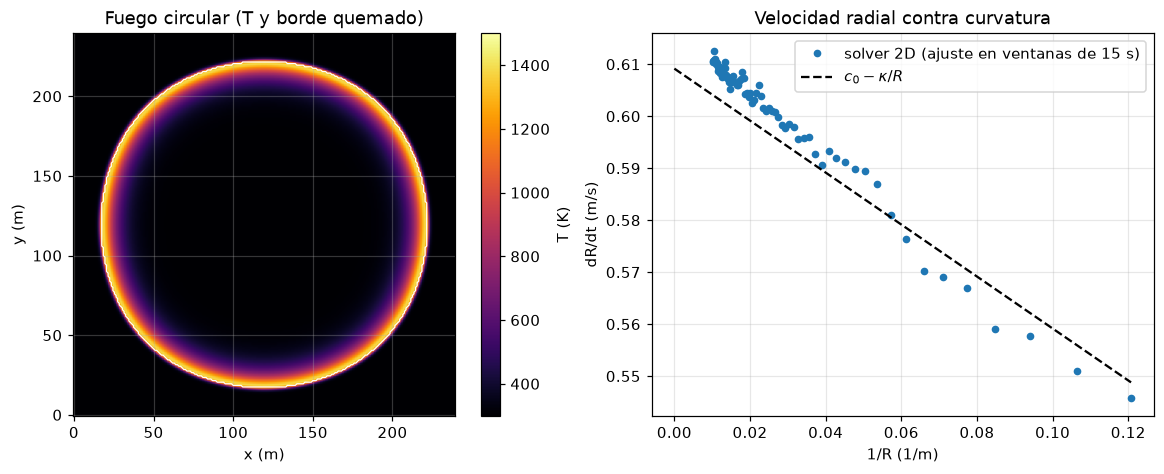

In [6]:
n = 240
sim = make_sim(Scene(np.zeros((n, n)), 1.0, np.zeros((0, 4))))
sim.ignite(n / 2, n / 2, 3.0)
rad_t, rad_r = [], []
while sim.t < 170:
    sim.step(4)
    rad_t.append(sim.t)
    rad_r.append(np.sqrt(sim.metrics()["burned_area"] / np.pi))
rad_t, rad_r = np.array(rad_t), np.array(rad_r)

burned = sim._burned()
c0 = n // 2
dirs = {"E": (0, 1), "O": (0, -1), "N": (1, 0), "S": (-1, 0), "NE": (1, 1), "NO": (1, -1), "SE": (-1, 1), "SO": (-1, -1)}
reach = {}
for name, (dr, dc) in dirs.items():
    k = 0
    while 0 <= c0 + (k + 1) * dr < n and 0 <= c0 + (k + 1) * dc < n and burned[c0 + (k + 1) * dr, c0 + (k + 1) * dc]:
        k += 1
    reach[name] = k * np.hypot(dr, dc)
vals = np.array(list(reach.values()))
display(Markdown("| Dirección | " + " | ".join(reach) + " |\n|" + "---|" * (len(reach) + 1) + "\n| Radio (m) | " +
                 " | ".join(f"{v:.1f}" for v in vals) + " |"))
anis = (vals.max() - vals.min()) / vals.mean()
print(f"Anisotropía (máx − mín)/media = {anis:.2%}")

# Area grows by whole cells, so fit dR/dt over sliding 15 s windows instead of differencing.
win = 15.0
mid_r, mid_v = [], []
for t_c in np.arange(rad_t[0] + win / 2, rad_t[-1] - win / 2, 2.0):
    sel = np.abs(rad_t - t_c) <= win / 2
    mid_v.append(np.polyfit(rad_t[sel], rad_r[sel], 1)[0])
    mid_r.append(np.interp(t_c, rad_t, rad_r))
mid_r, mid_v = np.array(mid_r), np.array(mid_v)
ok = mid_r > 8
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
im = ax[0].imshow(sim.T, origin="lower", cmap="inferno", vmin=300, vmax=1500)
ax[0].contour(burned, levels=[0.5], colors="w", linewidths=0.8)
ax[0].set(title="Fuego circular (T y borde quemado)", xlabel="x (m)", ylabel="y (m)")
fig.colorbar(im, ax=ax[0], label="T (K)")
kappa = sim.p.kappa
ax[1].plot(1 / mid_r[ok], mid_v[ok], "o", ms=4, label="solver 2D (ajuste en ventanas de 15 s)")
inv = np.linspace(0, (1 / mid_r[ok]).max(), 50)
ax[1].plot(inv, c_plane - kappa * inv, "k--", label=r"$c_0 - \kappa/R$")
ax[1].set(xlabel="1/R (1/m)", ylabel="dR/dt (m/s)", title="Velocidad radial contra curvatura")
ax[1].legend()
fig.savefig(FIG / "circulo_curvatura.png", bbox_inches="tight")
plt.show()

El círculo se mantiene isotrópico, con diferencias del orden de una celda entre direcciones. La velocidad radial crece hacia la del frente plano a medida que aumenta R, siguiendo de cerca la relación eikonal $c_0 - \kappa/R$. Por eso, en el simulador, la métrica `front_speed` de un incendio que empieza en un punto parte más baja y tiende a $c_0$.

In [7]:
summary = {
    "c_1d_converged": C_1D,
    "c_2d_dx1": c_plane,
    "mesh": rows,
    "observed_order": [o for o in orders if o is not None],
    "dt_sensitivity": dt_rows,
    "kappa_scaling": [{"kappa": k, "c": c} for k, c in k_rows],
    "kappa_ratio_spread": spread,
    "circle_reach_m": reach,
    "circle_anisotropy": anis,
}
(RES / "validacion_2d.json").write_text(json.dumps(summary, indent=2, default=float))
print(json.dumps({k: summary[k] for k in ("c_1d_converged", "c_2d_dx1", "observed_order", "kappa_ratio_spread", "circle_anisotropy")}, indent=2, default=float))

{
  "c_1d_converged": 0.6566302605659252,
  "c_2d_dx1": 0.6091588412596975,
  "observed_order": [
    1.2347246819372921,
    2.143402473398109,
    2.342129653466853
  ],
  "kappa_ratio_spread": 0.006915993692572317,
  "circle_anisotropy": 0.035611519388785345
}
